In [40]:
import numpy as np
import pandas as pd
from scipy.signal import butter, sosfiltfilt
from scipy.integrate import cumulative_trapezoid

# SETTINGS
FILE = "C:/Users/c25022289/Downloads/imu_test_data/IMU_Recording_2026-11-13T19-27-54-136Z.csv"
G = 9.80665

# Load CSV (requires columns named t and z)
data = pd.read_csv(FILE)
# Extract time in seconds
t = data["elapsed_seconds"].to_numpy(dtype=float)

# Extract Z acceleration
z = pd.to_numeric(
    data["z_raw"].astype(str).str.strip().str.replace("−", "-", regex=False),
    errors="coerce"
).to_numpy() / 1000 * G

# Calculate sampling frequency
dt = np.median(np.diff(t))
fs = 1 / dt

# 20 Hz low-pass Butterworth filter


LOW_CUTOFF = 0.05
HIGH_CUTOFF = 30.0

sos = butter(
    4,
    [LOW_CUTOFF, HIGH_CUTOFF],
    fs=fs,
    btype="bandpass",
    output="sos"
)
filtered = sosfiltfilt(sos, z)


# Integrate acceleration to get velocity
velocity = cumulative_trapezoid(filtered, t, initial=0)

# Find peak positive velocity
peak_index = np.argmax(velocity)
peak_velocity = velocity[peak_index]

# Estimate jump height
height = peak_velocity**2 / (2 * G)

print(f"Sampling frequency: {fs:.1f} Hz")
print(f"Peak positive velocity: {peak_velocity:.3f} m/s")
print(f"Estimated jump height: {height:.3f} m")
print(f"Estimated jump height: {height * 100:.1f} cm")
print(f"Peak velocity time: {t[peak_index]:.3f} s")

Sampling frequency: 512.0 Hz
Peak positive velocity: 2.522 m/s
Estimated jump height: 0.324 m
Estimated jump height: 32.4 cm
Peak velocity time: 1.338 s


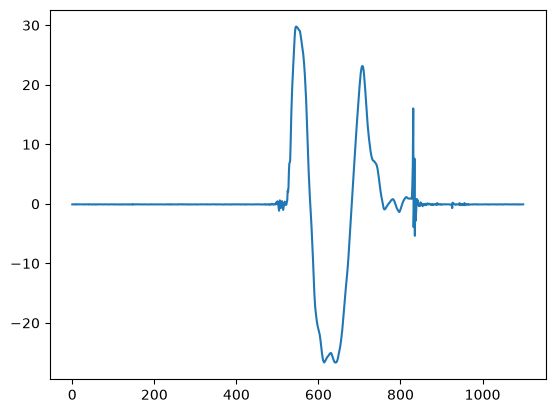

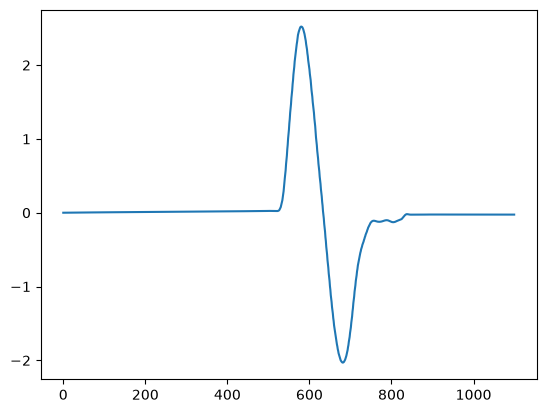

In [41]:
import matplotlib.pyplot as plt
plt.figure()
plt.plot(z)

plt.figure()
plt.plot(velocity)